# Anime faces: design, train, defend

**Final coding homework · independent take-home investigation · Chapters 10–12**

Create an unconditional model that generates **new RGB anime-face images from random codes**.
Choose a **VAE or GAN**, justify the choice, and train your own weights. You may adapt the course's
ideas and cite code you reuse, but you must understand and explain every model and training step.
A deterministic autoencoder with arbitrary normal sampling does not by itself meet the requirement.

This assignment deliberately leaves the architecture, objective implementation, training procedure,
and interpretation to you. There is no fill-in-the-blanks model or supplied trained solution.
Data auditing, split construction, plotting, diagnostic calculations, logging, and report rendering
are provided so your effort goes into the generative experiment.

**The scientific question:** what specific design decision will you test, and what evidence could show
that your initial expectation was wrong?

## Scope and deliverables

Build one working baseline and **one controlled variant**. Change one substantive factor, state a
prediction first, and compare under a declared matched budget. A small, carefully interpreted run is
better than an unexplained long run. Train from scratch; a pretrained face generator is not a submission.

Planning estimate: **4–6 hours of active work**, plus hardware-dependent training. This is not a
90-minute lab or a promise about convergence. Start with 32 × 32 or 64 × 64 pixels and a reproducible
subset. Reserve a modest budget before launching runs; there is no required number of epochs or GPU.
If compute is limited, use 32 × 32, fewer channels and fewer images for both runs, and report the limits.
You are assessed on design, correctness, evidence and reasoning—not a leaderboard score.

Submit:

1. The executed notebook with code, decisions, visible outputs, and cited assistance.
2. A self-contained **report.html** (roughly 1,200–1,800 words plus figures).
3. The data manifest, both run configurations and loss logs, evaluation JSON, and final model weights.
4. A short reproduction instruction: environment, dataset handle/path, selected run and sampling command.

Do not bundle the dataset. Due date and submission channel follow the instructor's announcement.

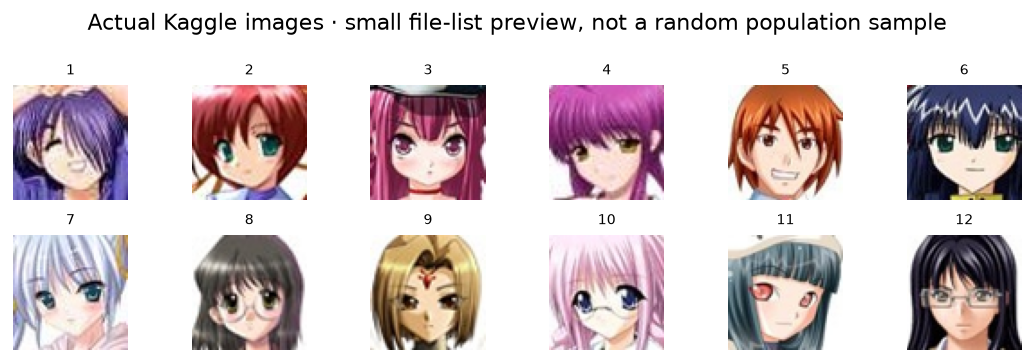

## 1 · Write the experiment plan before training

Record your answers in Markdown:

- **Question and hypothesis:** name one change and predict its effect and possible downside.
- **Model:** VAE or GAN? Why does its objective suit generation from fresh codes?
- **Architecture:** resolution, latent dimension, channel widths, activations, normalization and output range.
- **Controlled comparison:** what changes between A and B? What stays fixed: split, resolution, batch size,
  budget definition, initialization seed, data-order seed, sample codes and evaluation protocol?
- **Budget:** maximum steps or wall time per run, machine, checkpoint interval, and stopping rule.
- **Selection:** use validation evidence to select the model/checkpoint; reserve test images for final reporting.

Possible factors include latent dimension, channel capacity, G/D learning-rate ratio, or the VAE KL weight.
Choose one you can explain. Architecture and learning-rate changes together are not a single-factor study.
Do not introduce an unfamiliar loss merely because a tutorial uses it. Advanced methods are optional,
not assessed prerequisites; VAE and non-saturating GAN objectives are sufficient.

**Decision record:** write your hypothesis now, then append revisions with reasons. Do not rewrite your
initial prediction after seeing the outcomes. A result contradicting it can be a strong report.

In [ ]:
PLAN = {
    'student': '[WRITE your name]',
    'family': '[CHOOSE VAE or GAN]',
    'question': '[WRITE one testable question]',
    'hypothesis': '[WRITE predicted effect and risk]',
    'changed_factor': '[WRITE one factor]',
    'budget_rule': '[WRITE equal steps or equal wall time and why]',
    'selection_rule': '[WRITE validation-based checkpoint rule]',
}

## 2 · Prepare and audit the data (infrastructure provided)

Use [Anime Face Dataset on Kaggle](https://www.kaggle.com/datasets/splcher/animefacedataset), handle
`splcher/animefacedataset`. The uploader attributes the source to
[Mckinsey666/Anime-Face-Dataset](https://github.com/Mckinsey666/Anime-Face-Dataset), collected from Getchu.
Record the version/download date, source attribution, and listed terms in your report. The metadata
currently lists DbCL-1.0; check the page when downloading. **Measure your actual file counts** instead
of copying a count from the description. A dataset of these selected faces is not representative of all
anime art, characters or styles; inspect and discuss its selection biases.

Choose an access route:

- **Kaggle:** attach `splcher/animefacedataset` through Add Input, then point `DATA_ROOT` at its images.
- **Colab/local:** download and extract the dataset yourself, or use the optional `kagglehub` cell below.
- **Offline:** use a previously extracted copy and set its path. No model download is required.

Install missing packages once with `%pip install torch torchvision pillow numpy matplotlib kagglehub`.
Only `kagglehub` needs network access for the optional download; the assignment itself uses PyTorch,
Pillow, NumPy and Matplotlib. Keep API tokens in the platform's secret mechanism, not the notebook.
Authentication, when needed, is handled by Kaggle's normal login flow.

In [ ]:
# OPTIONAL DOWNLOAD: leave False if the dataset is already attached/extracted.
DOWNLOAD_DATA = False
if DOWNLOAD_DATA:
    import kagglehub
    downloaded_root = kagglehub.dataset_download('splcher/animefacedataset')
    print('Dataset folder:', downloaded_root)

The next cell defines the provided utilities. `FaceDataset` owns a root path, a list of manifest rows,
and a resolution. A row refers to an image file; indexing decodes a fresh tensor. A DataLoader batches
these tensors and shuffles **only training**. Model parameters are not stored in the dataset.

Default preprocessing: apply EXIF orientation, convert to RGB, center-crop a square and bicubic-resize.
The returned tensor is **(B, 3, H, W), float, [0,1]**. Adapt the range explicitly if your generator uses
Tanh. Exact duplicates after preprocessing are removed **before** the seeded 80/10/10 split; near
copies and related characters can remain. Augmentation is your choice, and must affect training only.

In [ ]:
"""Provided data, visualization, logging and report infrastructure.
No model, loss, optimizer step or trained checkpoint is supplied.
Images returned by the loader are RGB float tensors in [0,1].
"""
from pathlib import Path
import base64, csv, hashlib, html, json, platform, random, time
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

DATASET_HANDLE = 'splcher/animefacedataset'
DATASET_URL = 'https://www.kaggle.com/datasets/' + DATASET_HANDLE

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    return {'seed': seed, 'python': platform.python_version(), 'torch': str(torch.__version__),
            'device': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'}

def rgb_image(path, size):
    """EXIF orientation, RGB conversion, centered square crop and bicubic resize."""
    with Image.open(path) as source:
        return ImageOps.fit(ImageOps.exif_transpose(source).convert('RGB'),
                            (size, size), method=Image.Resampling.BICUBIC)

def prepare_data(root, out, size=64, max_images=8000, seed=120, fractions=(.8,.1,.1)):
    """Audit a seeded subset; remove exact processed-image duplicates BEFORE splitting.
    Near duplicates/related characters can remain. Lists store paths, not copied tensors.
    Reuse the saved manifest for every experiment; don't rerun a new split per model.
    """
    root=Path(root);out=Path(out);out.mkdir(parents=True,exist_ok=True)
    if len(fractions)!=3 or any(v<=0 for v in fractions) or not np.isclose(sum(fractions),1):
        raise ValueError('Use three positive train/validation/test fractions summing to one.')
    files=sorted(p for p in root.rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'})
    if not files: raise FileNotFoundError('No images found. Set DATA_ROOT to the extracted Kaggle image folder.')
    order=np.random.default_rng(seed).permutation(len(files))
    if max_images is not None: order=order[:max_images]
    kept=[];rejected=[];duplicates=[];seen={}
    for j in order:
        p=files[int(j)];rel=str(p.relative_to(root))
        try:
            with Image.open(p) as im: width,height=im.size;mode=im.mode
            image=rgb_image(p,size)
            digest=hashlib.sha256(image.tobytes()).hexdigest()
            if digest in seen:
                duplicates.append({'path':rel,'same_as':seen[digest]});continue
            seen[digest]=rel
            kept.append({'path':rel,'width':width,'height':height,'mode':mode,'pixel_sha256':digest})
        except (OSError,ValueError) as e: rejected.append({'path':rel,'reason':str(e)})
    if len(kept)<10: raise ValueError('Need at least 10 unique readable images to form all three splits.')
    n=len(kept);a=int(n*fractions[0]);b=a+int(n*fractions[1])
    parts={'train':kept[:a],'validation':kept[a:b],'test':kept[b:]}
    record={'dataset':DATASET_URL,'seed':seed,'size':size,'files_discovered':len(files),
            'candidates_scanned':len(order),'unique_retained':n,'rejected':rejected,'duplicates':duplicates,
            'preprocessing':'EXIF orientation; RGB; center-square crop; bicubic resize; uint8 / 255',
            'fractions':list(fractions),'splits':parts,
            'limitation':'Exact equality after preprocessing only; near-duplicate/character leakage not eliminated.'}
    (out/'data_manifest.json').write_text(json.dumps(record,indent=2))
    return record

class FaceDataset(Dataset):
    """Owns file paths and size; __getitem__ decodes one image into a new tensor."""
    def __init__(self, root, rows, size): self.root=Path(root);self.rows=rows;self.size=size
    def __len__(self): return len(self.rows)
    def __getitem__(self,i):
        im=rgb_image(self.root/self.rows[i]['path'],self.size)
        return torch.from_numpy(np.asarray(im).copy()).permute(2,0,1).float()/255

def make_loaders(root, manifest, batch_size=64, seed=121):
    datasets={k:FaceDataset(root,rows,manifest['size']) for k,rows in manifest['splits'].items()}
    generator=torch.Generator().manual_seed(seed)
    # num_workers=0 is portable across Kaggle, Colab and local notebooks.
    loaders={k:DataLoader(ds,batch_size=batch_size,shuffle=k=='train',num_workers=0,
                         generator=generator if k=='train' else None,drop_last=False)
             for k,ds in datasets.items()}
    return datasets,loaders

def collect(dataset, n=256):
    if n<1 or n>len(dataset): raise ValueError(f'n must be in [1,{len(dataset)}]')
    return torch.stack([dataset[i] for i in range(n)])

def checked_images(x):
    x=torch.as_tensor(x).detach().cpu().float()
    if x.ndim!=4 or x.shape[1]!=3 or len(x)==0: raise ValueError('Expected nonempty (N,3,H,W) RGB batch.')
    if not torch.isfinite(x).all() or x.min() < -1e-5 or x.max()>1+1e-5:
        raise ValueError('Convert outputs explicitly to [0,1]; nonfinite/out-of-range values are not silently clipped.')
    return x.clamp(0,1)

def save_grid(images, path, title='', nrow=8):
    x=checked_images(images);n=len(x);cols=min(nrow,n);rows=(n+cols-1)//cols
    fig,axes=plt.subplots(rows,cols,figsize=(cols*1.4,rows*1.4),squeeze=False)
    for i,ax in enumerate(axes.flat):
        ax.axis('off')
        if i<n: ax.imshow(x[i].permute(1,2,0).numpy());ax.set_title(str(i+1),fontsize=8)
    if title:fig.suptitle(title,fontsize=12)
    fig.tight_layout();Path(path).parent.mkdir(parents=True,exist_ok=True)
    fig.savefig(path,dpi=130,bbox_inches='tight');plt.close(fig)
    return Path(path)

class RunLog:
    """Stores scalar observations; students decide losses, updates and when to record."""
    def __init__(self, folder, config):
        self.folder=Path(folder);self.folder.mkdir(parents=True,exist_ok=True)
        self.started=time.perf_counter();self.rows=[]
        (self.folder/'config.json').write_text(json.dumps(config,indent=2))
    def record(self, step, **scalars):
        values={k:float(v) for k,v in scalars.items()}
        if not all(np.isfinite(v) for v in values.values()): raise ValueError('Nonfinite logged value: stop and diagnose.')
        self.rows.append({'step':int(step),'seconds':time.perf_counter()-self.started,**values})
        (self.folder/'history.json').write_text(json.dumps(self.rows,indent=2))
    def plot(self, path=None):
        if not self.rows:raise ValueError('No logged observations.')
        keys=sorted(set().union(*(r.keys() for r in self.rows))-{'step','seconds'})
        fig,axes=plt.subplots(len(keys),1,figsize=(8,2.5*len(keys)),squeeze=False)
        for ax,key in zip(axes.flat,keys):
            rows=[r for r in self.rows if key in r];ax.plot([r['step'] for r in rows],[r[key] for r in rows]);ax.set(xlabel='Optimizer iteration (declared convention)',ylabel=key);ax.grid(alpha=.2)
        fig.tight_layout();p=Path(path) if path else self.folder/'curves.png';fig.savefig(p,dpi=140);plt.close(fig);return p

def parameter_counts(models):
    return {name:sum(p.numel() for p in model.parameters()) for name,model in models.items()}

def save_checkpoint(path, models, optimizers, config, step):
    """Weights/optimizer state + config. Not an exact mid-epoch resume protocol."""
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    torch.save({'models':{k:v.state_dict() for k,v in models.items()},
                'optimizers':{k:v.state_dict() for k,v in optimizers.items()},
                'config':config,'step':int(step),'torch_rng':torch.get_rng_state()},path)
    return path

def pairwise_pixel_mse(images):
    """Mean pairwise pixel MSE over distinct pairs, not a perceptual quality metric."""
    x=checked_images(images).flatten(1).double();n=len(x)
    if n<2:raise ValueError('Need at least two images.')
    # Mean unordered-pair squared difference = 2n/(n-1) * population variance.
    return float(2*n/(n-1)*x.var(dim=0,unbiased=False).mean())

def nearest_pixels(queries, reference, chunk_size=128):
    q=checked_images(queries);r=checked_images(reference)
    if q.shape[1:]!=r.shape[1:]:raise ValueError('Match image shapes and preprocessing.')
    q=q.flatten(1);r=r.flatten(1);best=torch.full((len(q),),float('inf'));ids=torch.zeros(len(q),dtype=torch.long)
    # Bounded query/reference chunks; no (queries, references, pixels) allocation.
    for start in range(0,len(q),64):
        block=q[start:start+64];dist=torch.full((len(block),),float('inf'));idx=torch.zeros(len(block),dtype=torch.long)
        for j in range(0,len(r),chunk_size):
            rb=r[j:j+chunk_size];d=(block.square().mean(1)[:,None]+rb.square().mean(1)[None,:]-2*block@rb.T/block.shape[1]).clamp_min(0)
            v,k=d.min(1);update=v<dist;dist[update]=v[update];idx[update]=k[update]+j
        best[start:start+len(block)]=dist;ids[start:start+len(block)]=idx
    return {'mse':best,'index':ids}

def save_neighbors(queries, reference, result, path):
    q=checked_images(queries);r=checked_images(reference);n=min(8,len(q))
    fig,axes=plt.subplots(n,2,figsize=(5,n*2),squeeze=False)
    for i in range(n):
        for ax,im,label in [(axes[i,0],q[i],f'Query {i+1}'),(axes[i,1],r[int(result['index'][i])],f"Nearest · MSE {result['mse'][i]:.4f}")]:
            ax.imshow(im.permute(1,2,0));ax.set_title(label,fontsize=10);ax.axis('off')
    fig.tight_layout();fig.savefig(path,dpi=120);plt.close(fig);return Path(path)

def evaluate_samples(generated, train_reference, heldout_reference):
    """Same-size reference sets make NN comparisons less confounded by pool size."""
    g=checked_images(generated);t=checked_images(train_reference);h=checked_images(heldout_reference)
    if len(t)!=len(h):raise ValueError('Use equally sized train and held-out reference pools.')
    nt=nearest_pixels(g,t);nh=nearest_pixels(g,h)
    return {'generated_count':len(g),'reference_count_each':len(t),
            'generated_pairwise_pixel_mse':pairwise_pixel_mse(g),
            'heldout_pairwise_pixel_mse':pairwise_pixel_mse(h),
            'mean_nearest_train_pixel_mse':float(nt['mse'].mean()),
            'mean_nearest_heldout_pixel_mse':float(nh['mse'].mean())},nt,nh

def render_report(path, sections, config, metrics, figures):
    """Self-contained HTML; plain-text authored sections + embedded PNGs, printable to PDF.
    figures is a list of (path, caption). This renders evidence; it does not write conclusions.
    """
    esc=lambda x:html.escape(str(x))
    required=['Question','Dataset','Architecture','Training','Results and metrics','Limitations and conclusion','References']
    if any(not sections.get(k,'').strip() or '[WRITE' in sections[k] for k in required):
        raise ValueError('Write every report section; replace the [WRITE ...] placeholders.')
    document='<!doctype html><html lang="en"><meta charset="utf-8"><title>Anime face generation · Experimental report</title><style>body{max-width:960px;margin:3rem auto;padding:0 1.4rem;font:17px/1.6 system-ui;color:#17212b}h1{font-size:2rem}h2{margin-top:2rem;color:#2878c8}p{white-space:pre-wrap}img{max-width:100%}figure{margin:2rem 0}figcaption{font-size:.9rem}table{border-collapse:collapse;width:100%}td,th{padding:.5rem;border-bottom:1px solid #ccc;text-align:left;overflow-wrap:anywhere}pre{white-space:pre-wrap;background:#f5f1e8;padding:1rem}@media print{body{font-size:10pt;margin:0;max-width:none}figure,table{break-inside:avoid}h2{break-after:avoid}@page{size:A4;margin:18mm}}</style><body><h1>Anime face generation</h1><p>Experimental report · student-authored analysis</p>'
    for title in required:
        document+=f'<h2>{esc(title)}</h2><p>{esc(sections[title])}</p>'
        if title=='Training':document+='<pre>'+esc(json.dumps(config,indent=2))+'</pre>'
        if title=='Results and metrics':
            document+='<table><tr><th>Run</th><th>Measurement</th><th>Value</th></tr>'
            for run,values in metrics.items():
                for key,value in values.items():document+=f'<tr><td>{esc(run)}</td><td>{esc(key)}</td><td>{esc(value)}</td></tr>'
            document+='</table>'
            for file,caption in figures:
                file=Path(file)
                if file.suffix.lower()!='.png':raise ValueError('Report figures must be PNG.')
                encoded=base64.b64encode(file.read_bytes()).decode()
                document+=f'<figure><img src="data:image/png;base64,{encoded}" alt="{esc(caption)}"><figcaption>{esc(caption)}</figcaption></figure>'
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True);path.write_text(document+'</body></html>');return path

In [ ]:
DATA_ROOT = Path('/kaggle/input/animefacedataset')  # EDIT to the actual image folder
OUTPUT = Path('anime_results')
OUTPUT.mkdir(exist_ok=True)
ENVIRONMENT = seed_everything(120)
print(ENVIRONMENT)

# Suggested starting scale, not mandatory design choices.
IMAGE_SIZE = 64
MAX_IMAGES = 8000  # deterministic subset BEFORE duplicate removal and splitting
manifest = prepare_data(DATA_ROOT, OUTPUT, size=IMAGE_SIZE, max_images=MAX_IMAGES, seed=120)
datasets, loaders = make_loaders(DATA_ROOT, manifest, batch_size=64, seed=121)
print({name: len(ds) for name, ds in datasets.items()})
print('Rejected:', len(manifest['rejected']), 'Exact duplicates removed:', len(manifest['duplicates']))
real_batch = next(iter(loaders['train']))
assert real_batch.ndim == 4 and real_batch.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(real_batch).all() and 0 <= real_batch.min() <= real_batch.max() <= 1
save_grid(real_batch[:32], OUTPUT/'dataset_preview.png', 'Training subset preview')
from IPython.display import display
from IPython.display import Image as DisplayImage
display(DisplayImage(filename=str(OUTPUT/'dataset_preview.png')))

**Dataset report:** give discovered/scanned/retained counts, corrupt/duplicate exclusions, split counts,
original size range, preprocessing and rationale. Inspect the preview: what information does center
cropping discard? Do backgrounds, repeated characters or style concentration create easy shortcuts?
State the limitation of the duplicate check. Keep this manifest fixed across A/B. The helper caps data
before splitting, so MAX_IMAGES is a candidate-subset cap, not the final training count.

**Expected checks:** nonempty disjoint manifests; RGB batches at the selected size; finite [0,1]
values; no shared retained pixel hash between splits. These checks do not establish dataset diversity.

In [ ]:
hashes = {k: {r['pixel_sha256'] for r in rows} for k, rows in manifest['splits'].items()}
assert not hashes['train'] & hashes['validation']
assert not hashes['train'] & hashes['test']
assert not hashes['validation'] & hashes['test']
# Your audit summary and any justified changes to preparation go here.

## 3 · Design and implement your model

Draw your architecture **before** training: tensor shapes, operations, channels, activations and parameter
counts. Explain how resolution grows in the generator/decoder and shrinks in the discriminator/encoder.
Keep the notation separate from measured activations. Include the diagram in the report.

You decide the module organization. Implement your model(s), objective and optimizers below. Provide
an adapter `sample_from_codes(models, z)` that accepts `(N, latent_dim)` standard-normal codes and
returns `(N, 3, IMAGE_SIZE, IMAGE_SIZE)` images in **[0,1]**. This adapter should use evaluation mode and
`no_grad`; reshape codes for a convolutional G as needed. It must generate without consuming a real image.

For a **GAN**, explain source targets, raw logits, non-saturating G loss, gradient routing, separate
optimizer ownership, and normalization-buffer behavior. For a **VAE**, explain the posterior parameters,
reparameterization, reconstruction likelihood/surrogate, KL and loss reductions; sample from the prior
through the decoder. A deterministic mean-code reconstruction is not a fresh generated sample.

You may consult the course code and primary papers. Cite adapted code and identify what you changed.
Do not copy an entire online training notebook and present it as your own design.

In [ ]:
# STUDENT WORK: modules, objective functions and optimizer construction.
# Add as many cells as you need; no architecture or loss is supplied here.

def build_models(config):
    raise NotImplementedError('Design and return a dictionary of your PyTorch models.')

def sample_from_codes(models, z):
    raise NotImplementedError('Generate RGB [0,1] images from codes, with eval mode and no_grad.')

**Before a long run:** verify generation at batch sizes 1 and 4; output range and finiteness; nonzero
parameter counts; intended gradients and parameter changes after one update. For a GAN, verify each
turn changes only its owned parameters. For a VAE, test the reconstruction gradient path separately
from the KL term. Verify a saved/reloaded model reproduces evaluation-mode output for fixed codes.
These checks are your responsibility; document the evidence, not only “the code ran.”

In [ ]:
# EDIT config values and include every choice needed to reconstruct the model.
BASE_CONFIG = {
    'family': PLAN['family'], 'image_size': IMAGE_SIZE, 'latent_dim': 64,
    'seed': 122, 'data_order_seed': 121, 'batch_size': 64,
    'max_steps': 1000, 'max_seconds': 1800,  # starting caps; justify your actual budget
    # Add widths, activations, optimizer settings, losses/reductions and mode policy.
}
models = build_models(BASE_CONFIG)
print(parameter_counts(models))
for n in [1, 4]:
    # Your adapter is responsible for moving z to the model's device.
    z = torch.randn(n, BASE_CONFIG['latent_dim'])
    samples = checked_images(sample_from_codes(models, z))
    assert samples.shape == (n, 3, IMAGE_SIZE, IMAGE_SIZE)
# Add your one-update ownership/gradient checks and checkpoint round-trip check.

## 4 · Train a baseline and one controlled variant

Implement `train_model(config, train_loader, validation_loader, folder)` yourself. Return the trained
model dictionary. You own the training loop, objectives, optimizer steps, mode transitions and stopping.
The helper `RunLog` records scalars; it does not train. Use the same step or time convention in both runs.

Your loop should: respect both caps after each batch; record actual elapsed time and updates; save
checkpoints and fixed-code sample grids at declared intervals; keep validation free of optimizer updates;
and stop to investigate nonfinite losses. Restore training mode after making evaluation snapshots.
A wall-time cap is checked between batches and cannot interrupt a slow operation already in progress.

**What to log:** GAN D/G losses separately with their reductions, or VAE reconstruction/KL/total losses;
learning rate(s), examples seen, update count, elapsed time, and validation observations used for selection.
Do not call adversarial source accuracy an image-quality metric. Do not compare a VAE objective numerically
with a GAN objective as though lower meant better images.

Example use of provided logging (integrate into your own loop):

```python
log = RunLog(folder, config)
# after your update:
log.record(step, loss_D=loss_D.item(), loss_G=loss_G.item())  # GAN example
# or log reconstruction, KL and total for a VAE
log.plot()
save_checkpoint(Path(folder)/'checkpoint.pt', models, optimizers, config, step)
```

`save_checkpoint` stores model/optimizer states and configuration. Exact mid-epoch resumption also
needs your data-order and all relevant RNG states; do not claim exact resume from this helper alone.

In [ ]:
# STUDENT WORK: implement a bounded training loop. No training recipe is hidden in support.py.
def train_model(config, train_loader, validation_loader, folder):
    raise NotImplementedError('Implement training, validation selection, checkpoints and logging.')

VARIANT_CONFIG = dict(BASE_CONFIG)
# Change ONE justified factor here and add it to BASE_CONFIG too.
# Example structure only: VARIANT_CONFIG['chosen_factor'] = your_alternative
assert VARIANT_CONFIG != BASE_CONFIG, 'Define your controlled variant before launching it.'

runs = {}
for label, config in [('A', BASE_CONFIG), ('B', VARIANT_CONFIG)]:
    seed_everything(config['seed'])
    _, run_loaders = make_loaders(DATA_ROOT, manifest, config['batch_size'], config['data_order_seed'])
    runs[label] = train_model(config, run_loaders['train'], run_loaders['validation'], OUTPUT/label)
# Record actual compute, stopped step, checkpoint selection and failures for each run.

If the hardware cannot reach convincing faces within your declared budget, retain the results and
analyze the failure. A smaller matched comparison with correct mechanics and honest evidence is acceptable.
Do not extend only the better-looking run without reporting that the budget has changed. One run per
configuration is exploratory evidence, not a statistically established improvement; a second seed is
welcome if it fits the same budget.

## 5 · Evaluate without selecting only attractive samples

For A and B, show the same first 64 evaluation draws and fixed-code histories. If latent dimension is
the changed factor, use seeded draws in each space and explain why columns are not the same codes.
For final reporting, use a new draw seed and the untouched test reference **after** selecting your run
using validation. Keep all generated samples, including failures. Mark any curated gallery separately.

Required evidence:

1. Data preview and an architecture diagram with shapes/parameter counts.
2. Loss curves with step axes, reductions and compute budgets.
3. At least two fixed-code checkpoints and uncurated 64-sample grids for A/B.
4. A metrics table with sample counts, resolution, preprocessing, reference selection and limitations.
5. First eight query/nearest-training-image pairs; inspect failures and suspicious resemblance.

The supplied numerical diagnostics use concepts already covered in the course: squared pixel distance,
means, and nearest neighbors. **They are not fidelity metrics or a GAN leaderboard.**

For $N$ images with $P=3HW$ pixel values, mean pairwise MSE is

$$D_{\mathrm{pixel}}=\frac{2}{N(N-1)}\sum_{i<j}\frac{\|x_i-x_j\|_2^2}{P}.$$

It detects literal repetition but ignores semantic quality; random noise can score highly. Nearest-image
MSE can reveal suspicious copying but is sensitive to alignment and cannot prove memorization or novelty.
Use equal-sized train and held-out reference pools to avoid a larger pool automatically having more
opportunities for close matches. The search is exhaustive **within the declared pools**, not necessarily
the whole dataset. Report their sizes. Increasing sample count changes the evidence, not just precision.

FID/KID or other unfamiliar metrics are **optional external analyses**, not assessed requirements.
If used, cite the implementation, feature extractor/domain, preprocessing, counts and limitations; do
not compare scores obtained under different protocols. A generic photo feature space may poorly reflect
anime-specific visual quality. No extra credit comes from an unexplained metric name.

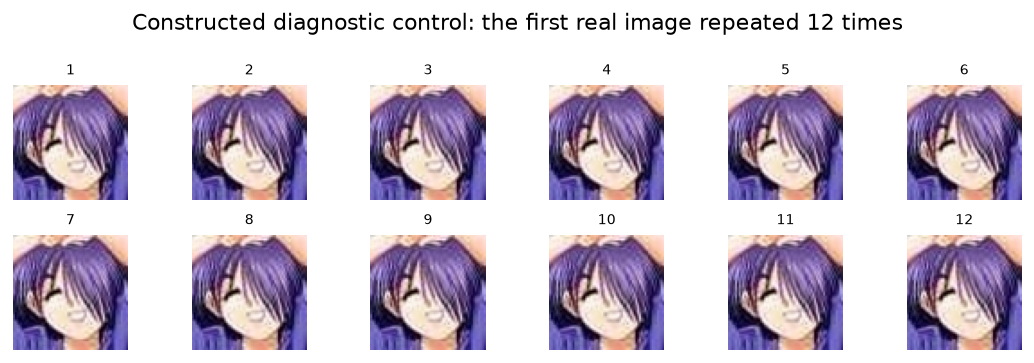

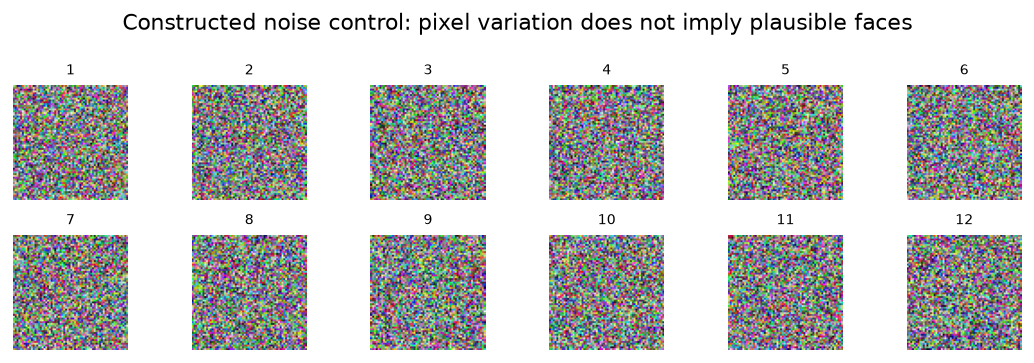

**Measured diagnostic sanity check** on the provided 12-image preview at 64 × 64 RGB:

| Input | Mean pairwise pixel MSE |
|---|---:|
| Actual file-list preview | 0.144963 |
| Exact repeated-image control | 0.000000 |
| Seeded uniform-noise control | 0.166143 |

These values validate the calculation and expose its limitations. They are **not targets for student
models** and do not evaluate a trained anime generator. The preview is too small and non-random to be a
dataset benchmark. Your reference pools must come from your saved split.

In [ ]:
# Provided evaluation infrastructure. Run only after completing your model/training cells.
# These are DEVELOPMENT comparisons; test images remain unused here.
reference_n = min(512, len(datasets['train']), len(datasets['validation']))
train_ref = collect(datasets['train'], reference_n)
validation_ref = collect(datasets['validation'], reference_n)
configs = {'A': BASE_CONFIG, 'B': VARIANT_CONFIG}
metrics = {}
for label, model_dict in runs.items():
    z = torch.randn(256, configs[label]['latent_dim'], generator=torch.Generator().manual_seed(125))
    generated = checked_images(sample_from_codes(model_dict, z))
    metrics[label], near_train, near_val = evaluate_samples(generated, train_ref, validation_ref)
    save_grid(generated[:64], OUTPUT/label/'fresh.png', f'{label}: first 64 of 256 development draws')
    save_neighbors(generated[:8], train_ref,
                   {'mse':near_train['mse'][:8], 'index':near_train['index'][:8]}, OUTPUT/label/'nearest.png')
    (OUTPUT/label/'evaluation.json').write_text(json.dumps(metrics[label], indent=2))
print(json.dumps(metrics, indent=2))
# Interpret the numbers together with the images. Do not select by maximizing pixel diversity.

In [ ]:
# STUDENT DECISION: use your predeclared validation evidence and explain your choice.
SELECTED_RUN = '[CHOOSE A or B]'
SELECTION_REASON = '[WRITE the evidence and trade-off]'
assert SELECTED_RUN in runs and '[WRITE' not in SELECTION_REASON
n = min(512, len(datasets['train']), len(datasets['test']))
final_z = torch.randn(256, configs[SELECTED_RUN]['latent_dim'], generator=torch.Generator().manual_seed(126))
final_images = checked_images(sample_from_codes(runs[SELECTED_RUN], final_z))
final_metrics, final_nn, _ = evaluate_samples(final_images, collect(datasets['train'], n), collect(datasets['test'], n))
save_grid(final_images[:64], OUTPUT/'final_samples.png', 'Selected model: first 64 fresh final draws')
(OUTPUT/'final_evaluation.json').write_text(json.dumps({'selected_run':SELECTED_RUN,
    'reason':SELECTION_REASON,'seed':126,'metrics':final_metrics}, indent=2))
# Do not return to model tuning after viewing test results without disclosing that reuse.

## 6 · Write and render the report

The report must be readable without running the notebook. Use this structure:

| Section | Evidence and explanation expected |
|---|---|
| Question | Hypothesis, changed factor, reason for model family, and what would falsify the prediction |
| Dataset | Kaggle source/version/date, attribution, measured counts, split, preprocessing, exclusions and biases |
| Architecture | Your diagram, tensor shapes, parameter counts, output range, objective formulas and reductions |
| Training | Hardware/software, seeds, optimizer(s), learning rates, batch size, updates/epochs/time, modes, checkpoint selection and failures |
| Results and metrics | A/B evidence under the same protocol, sample counts, curves, uncurated images, nearest neighbors, and interpretation |
| Limitations and conclusion | What changed, alternative explanations, missing evidence, compute limits and one justified next experiment |
| References | Dataset, papers, reused code, and disclosed external/AI assistance |

Captions should identify the run/checkpoint, sample-selection rule, and what a reader should inspect.
Distinguish observations from explanations: “the mouths repeat in 20 of 64 draws” is different from
“the discriminator is too strong.” What extra experiment would support the latter claim?

Fill the report sections below in your own words. The renderer only formats your writing and embeds
figures; it does not write the analysis. Add your architecture PNG and checkpoint-history figure to the
figure list. `report.html` is self-contained and can be opened offline. Use your browser's Print → Save
as PDF if a PDF is requested; use a figure appendix if needed rather than shrinking the evidence.

In [ ]:
REPORT = {
    'Question': '[WRITE your question, hypothesis, family choice and controlled change]',
    'Dataset': '[WRITE measured audit, source/date, split and preprocessing rationale]',
    'Architecture': '[WRITE model structure, dimensions, objective and parameter counts]',
    'Training': '[WRITE actual configuration, hardware, timing, modes and checkpoint rule]',
    'Results and metrics': '[WRITE quantitative and visual comparison, including failures]',
    'Limitations and conclusion': '[WRITE supported conclusions, caveats and next experiment]',
    'References': '[WRITE dataset/papers/code URLs and assistance attribution]',
}
FIGURES = [
    (OUTPUT/'dataset_preview.png', 'Replace with your informative dataset caption.'),
    (OUTPUT/'architecture.png', 'Your architecture, tensor dimensions and parameter counts.'),
    (OUTPUT/'A'/'curves.png', 'Baseline loss curves: state units and reduction.'),
    (OUTPUT/'B'/'curves.png', 'Variant loss curves under the declared matched budget.'),
    (OUTPUT/'fixed_history.png', 'Your fixed-code checkpoint comparison and selection rule.'),
    (OUTPUT/'A'/'fresh.png', 'Baseline: first 64 development draws, seed 125.'),
    (OUTPUT/'B'/'fresh.png', 'Variant: first 64 development draws, seed 125.'),
    (OUTPUT/SELECTED_RUN/'nearest.png', 'First eight development queries and nearest training references; state pool size.'),
    (OUTPUT/'final_samples.png', 'Selected model: first 64 final draws, seed 126; no quality filtering.'),
]
report_path = render_report(OUTPUT/'report.html', REPORT,
    {'plan':PLAN,'environment':ENVIRONMENT,'A':BASE_CONFIG,'B':VARIANT_CONFIG},
    {**metrics,'selected_test':final_metrics}, FIGURES)
print('Open:', report_path.resolve())
# In Colab: from google.colab import files; files.download(str(report_path))

**Other export routes.** The ZIP also contains `report_template.qmd`. Fill it with the same evidence,
then use `quarto render report_template.qmd --to html` (or `--to pdf` with a LaTeX installation).
To export your executed notebook as a technical appendix, run
`jupyter nbconvert --to html --embed-images anime_faces_homework.ipynb`.
The notebook appendix does not replace the focused experimental report.

**Submission check:** restart and run your finished notebook in order, or clearly mark expensive training
cells and provide checkpoint-loading cells for reproducing evaluation. Include exact preprocessing,
architecture/config, model weights and a fixed-code sampling check. Open report.html in a fresh browser
and verify every figure is embedded. Remove credentials and dataset files from the submission bundle.
Do not claim that a blank starter notebook or a supplied diagnostic control is your model's result.

## Assessment (100 points)

| Criterion | Points |
|---|---:|
| Dataset audit, split discipline and preprocessing justification | 15 |
| Model/objective correctness and architecture explanation | 25 |
| Training implementation, bounded experiment, logs and reproducibility | 20 |
| Controlled comparison, complementary evidence and metric interpretation | 25 |
| Clear report, limitations, citations and ownership of decisions | 15 |

There is no required fidelity score. More GPU time, more epochs, a fancier model name, or a successful-looking
single image does not substitute for the assessed evidence. Report failures honestly and diagnose them.

## Reading path

- [Course VAE notes](https://anassbelcaid.github.io/deeplearning-course/notes/11-variational-autoencoders/): posterior, reparameterization, likelihood and KL.
- [Course GAN notes](https://anassbelcaid.github.io/deeplearning-course/notes/12-generative-adversarial-networks/): logits, update ownership, convolutional shapes and evaluation.
- [Kingma & Welling](https://arxiv.org/abs/1312.6114): VAE objective and inference.
- [Goodfellow et al.](https://arxiv.org/abs/1406.2661): adversarial objectives and alternating optimization.
- [Radford et al.](https://arxiv.org/abs/1511.06434): convolutional GAN design choices.
- [Theis et al.](https://arxiv.org/abs/1511.01844): evaluation depends on the claim and intended use.
- [Kaggle dataset](https://www.kaggle.com/datasets/splcher/animefacedataset), [KaggleHub](https://github.com/Kaggle/kagglehub), and [PyTorch reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html): source access and implementation contracts.